# Stroke Risk Factor Analysis

**Goal:** find out which patient characteristics are most strongly associated with stroke, so that screening and prevention can be prioritised.

**Questions**
1. How does the stroke rate change with **age**?
2. How much higher is the rate for patients with **hypertension**, **heart disease** or **high blood glucose**?
3. Do **smoking, BMI, work type or gender** show a clear link with stroke?

**Dataset:** public *Stroke Prediction* healthcare dataset (5,110 patients, 12 columns). The copy used here had inconsistent text formatting (mixed case, stray spaces, spelling variants), so cleaning is a major part of this notebook. The dataset does not state a city or hospital, so the results describe this sample only.

**Method notes**
- Groups are compared by **stroke rate** (strokes divided by patients in the group, shown as a %), not by raw counts, because groups differ in size.
- The analysis is descriptive and observational: it shows associations, not causes.

## 1. Setup

Import the libraries used in the notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load and audit the raw data

Load the CSV and check its size, data types, summary statistics and missing values before changing anything.

In [2]:
df = pd.read_csv(r"C:\Users\HomePC\Downloads\healthcare-dataset-stroke-data%20(1)_MESSED (1).csv")

In [4]:
df['gender'].unique()

array(['male', 'Female', 'Male', ' Female', 'FEMALE', 'Female ', 'MALE',
       'female', 'Male ', ' male', ' Male ', ' Male', ' Female ',
       ' female', 'MALE ', ' MALE', ' female ', 'FEMALE ', 'male ',
       ' FEMALE', ' MALE ', 'female ', ' male ', ' FEMALE ', 'Other'],
      dtype=object)

In [5]:
df['age'].sum()

np.float64(220888.0)

In [3]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,male,67.0,0,1,Yes,private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,self-employed,Rural,202.21,NaN,Never Smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,neversmoked,1
3,60182,Female,49.0,0,0,Yes,Private,URBAN,171.23,34.4,smokes,1
4,1665,FEMALE,79.0,1,0,Yes,Self-Employed,Rural,174.12,24.0,never smoked,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [6]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

**What the audit shows**
- 5,110 patients and 12 columns.
- Only one column has missing values: `bmi` (201 missing, about 4%).
- About 4.9% of patients had a stroke (mean of the `stroke` column), so stroke is rare in this sample.
- Ages range from 0.08 years (infants) to 82.

### The formatting problem

Text columns contain the same value written in many ways (upper/lower case, leading and trailing spaces, missing spaces). If left alone, each spelling would be counted as a separate category and every group total and rate would be wrong.

In [7]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [8]:
df.columns = (df.columns
      .str.strip()                     
      .str.title()) 

## 3. Cleaning

### 3.1 Standardise column names and text values

Column names are cleaned first. Then 0/1 flags are turned into No/Yes, and text columns are fixed one at a time: set the case, strip stray spaces, and correct spelling variants (e.g. `Neversmoked` becomes `Never Smoked`). Each `.unique()` check confirms the column now has only its real categories.

In [9]:
df['Hypertension'] = df['Hypertension'].replace({0:'No', 1:'Yes'})
df['Heart_Disease'] = df['Heart_Disease'].replace({0:'No', 1:'Yes'})

In [10]:
df['Ever_Married'] = df['Ever_Married'].str.title()
df['Work_Type'] = df['Work_Type'].str.title()
df['Residence_Type'] = df['Residence_Type'].str.title()
df['Smoking_Status'] = df['Smoking_Status'].str.title()

In [11]:
df['Hypertension'].unique()

array(['No', 'Yes'], dtype=object)

In [12]:
df['Ever_Married'].unique()

array(['Yes', 'No', ' Yes', 'No ', 'Yes ', ' Yes ', ' No', ' No '],
      dtype=object)

In [13]:
df['Heart_Disease'].unique()

array(['Yes', 'No'], dtype=object)

In [14]:
df['Ever_Married'] = df['Ever_Married'].str.strip()

In [15]:
df['Work_Type'].unique()

array(['Private', 'Self-Employed', 'Private ', 'Govt_Job ',
       ' Self-Employed', 'Govt_Job', ' Private', 'Self-Employed ',
       ' Govt_Job', 'Children', ' Private ', 'Never_Worked',
       ' Self-Employed ', ' Children', 'Children ', ' Govt_Job ',
       ' Children ', 'Never_Worked '], dtype=object)

In [16]:
df['Work_Type'] = df['Work_Type'].str.strip()

In [17]:
df['Work_Type'].unique()

array(['Private', 'Self-Employed', 'Govt_Job', 'Children', 'Never_Worked'],
      dtype=object)

In [18]:
df['Work_Type'] = df['Work_Type'].str.replace("-", "_")

In [19]:
df['Work_Type'].unique()

array(['Private', 'Self_Employed', 'Govt_Job', 'Children', 'Never_Worked'],
      dtype=object)

In [20]:
df['Work_Type'] = df['Work_Type'].str.replace("_", " ")

In [21]:
df['Residence_Type'].unique()

array(['Urban', 'Rural', ' Rural', 'Urban ', 'Rural ', ' Urban',
       ' Urban ', ' Rural '], dtype=object)

In [22]:
df['Residence_Type'] = df['Residence_Type'].str.strip()

In [23]:
df['Residence_Type'].unique()

array(['Urban', 'Rural'], dtype=object)

In [24]:
df['Smoking_Status'].unique()

array([' Formerly Smoked', 'Never Smoked', 'Neversmoked', 'Smokes',
       'Formerly Smoked', 'Unknown', 'Never Smoked ', ' Smokes',
       ' Never Smoked', 'Formerlysmoked', ' Unknown', 'Formerly Smoked ',
       'Smokes ', ' Never Smoked ', 'Unknown ', ' Unknown ', ' Smokes ',
       ' Formerly Smoked '], dtype=object)

In [25]:
df['Smoking_Status'] = df['Smoking_Status'].str.strip()

In [26]:
df['Smoking_Status'].unique()

array(['Formerly Smoked', 'Never Smoked', 'Neversmoked', 'Smokes',
       'Unknown', 'Formerlysmoked'], dtype=object)

In [27]:
df['Smoking_Status'] = df['Smoking_Status'].replace(
{'Formerlysmoked' : 'Formerly Smoked',
 'Neversmoked' : 'Never Smoked'})

In [28]:
df['Smoking_Status'].unique()

array(['Formerly Smoked', 'Never Smoked', 'Smokes', 'Unknown'],
      dtype=object)

In [29]:
df['Bmi'].median()

28.1

In [30]:
df['Bmi'] = df['Bmi'].fillna(df['Bmi'].median())

In [31]:
df.head()

,Id,Gender,Age,Hypertension,Heart_Disease,Ever_Married,Work_Type,Residence_Type,Avg_Glucose_Level,Bmi,Smoking_Status,Stroke
0,9046,male,67.0,No,Yes,Yes,Private,Urban,228.69,36.6,Formerly Smoked,1
1,51676,Female,61.0,No,No,Yes,Self Employed,Rural,202.21,28.1,Never Smoked,1
2,31112,Male,80.0,No,Yes,Yes,Private,Rural,105.92,32.5,Never Smoked,1
3,60182,Female,49.0,No,No,Yes,Private,Urban,171.23,34.4,Smokes,1
4,1665,FEMALE,79.0,Yes,No,Yes,Self Employed,Rural,174.12,24.0,Never Smoked,1


In [32]:
df['Gender'] = (df.Gender
      .str.strip()                     
      .str.title())

### 3.2 Missing BMI and analysis groups

The 201 missing BMI values are filled with the overall median BMI (28.1) in section 3.1. Then numeric columns are grouped into categories so rates can be compared: age groups, BMI categories (Underweight, Normal, Overweight, Obese) and glucose levels (Low, Normal, High).

In [33]:
df['Age_Group']=pd.cut(df['Age'],
                       bins=[0, 20, 40, 60,100],
                       labels=['0-20', '21-40', '41-60', 'Above 60'],
                       include_lowest=True)

Age is kept as a decimal (children have ages such as 0.08 years) rather than being truncated to whole years.

In [34]:
df['Gender'].unique()

array(['Male', 'Female', 'Other'], dtype=object)

In [35]:
bins = [0, 18.5, 25, 30, float('inf')]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df['BMI_Category'] = pd.cut(df['Bmi'], bins=bins, labels=labels)

In [36]:
bins = [0, 70, 140, float('inf')]
labels = ['Low', 'Normal', 'High']
df['Glucose_Level_Category'] = pd.cut(df['Avg_Glucose_Level'], bins=bins, labels=labels, include_lowest=True)

### 3.3 Create the age group used in the analysis

A second, simpler age grouping (0-20, 21-40, 41-60, 61+) is used for the analysis below, since it makes the age pattern easier to read.

In [37]:
df.head()

,Id,Gender,Age,Hypertension,Heart_Disease,Ever_Married,Work_Type,Residence_Type,Avg_Glucose_Level,Bmi,Smoking_Status,Stroke,Age_Group,BMI_Category,Glucose_Level_Category
0,9046,Male,67.0,No,Yes,Yes,Private,Urban,228.69,36.6,Formerly Smoked,1,Above 60,Obese,High
1,51676,Female,61.0,No,No,Yes,Self Employed,Rural,202.21,28.1,Never Smoked,1,Above 60,Overweight,High
2,31112,Male,80.0,No,Yes,Yes,Private,Rural,105.92,32.5,Never Smoked,1,Above 60,Obese,Normal
3,60182,Female,49.0,No,No,Yes,Private,Urban,171.23,34.4,Smokes,1,41-60,Obese,High
4,1665,Female,79.0,Yes,No,Yes,Self Employed,Rural,174.12,24.0,Never Smoked,1,Above 60,Normal,High


In [38]:
df["Age Group"] = pd.cut(df["Age"], bins=[0, 20, 40, 60, 120], labels=["0-20", "21-40", "41-60", "61+"],
                         include_lowest=True)


## 4. Stroke rate by risk factor

For each factor, the first cell gives the **stroke rate (%)** per group. The bar chart that follows shows the **number of stroke cases** per group. Read the chart together with the rate table above it: large groups naturally have more cases, so the rate is the fair comparison.

### 4.1 Gender

In [39]:
Stroke_by_Gender = (df.groupby('Gender')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_Gender

Gender
Male      5.106383
Female    4.709419
Other     0.000000
Name: Stroke, dtype: float64

In [40]:
df.head()

,Id,Gender,Age,Hypertension,Heart_Disease,Ever_Married,Work_Type,Residence_Type,Avg_Glucose_Level,Bmi,Smoking_Status,Stroke,Age_Group,BMI_Category,Glucose_Level_Category,Age Group
0,9046,Male,67.0,No,Yes,Yes,Private,Urban,228.69,36.6,Formerly Smoked,1,Above 60,Obese,High,61+
1,51676,Female,61.0,No,No,Yes,Self Employed,Rural,202.21,28.1,Never Smoked,1,Above 60,Overweight,High,61+
2,31112,Male,80.0,No,Yes,Yes,Private,Rural,105.92,32.5,Never Smoked,1,Above 60,Obese,Normal,61+
3,60182,Female,49.0,No,No,Yes,Private,Urban,171.23,34.4,Smokes,1,41-60,Obese,High,41-60
4,1665,Female,79.0,Yes,No,Yes,Self Employed,Rural,174.12,24.0,Never Smoked,1,Above 60,Normal,High,61+


### 4.2 Age group

In [41]:
Stroke_by_Age_Group = (df.groupby('Age Group')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_Age_Group

C:\Users\HomePC\AppData\Local\Temp\ipykernel_18404\1157567975.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Stroke_by_Age_Group = (df.groupby('Age Group')['Stroke'].mean()*100).sort_values(ascending=False)


Age Group
61+      13.573620
41-60     4.097311
21-40     0.492207
0-20      0.195122
Name: Stroke, dtype: float64

C:\Users\HomePC\AppData\Local\Temp\ipykernel_18404\2439534178.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Stroke_by_Age_Group = df.groupby('Age Group')['Stroke'].sum().reset_index()


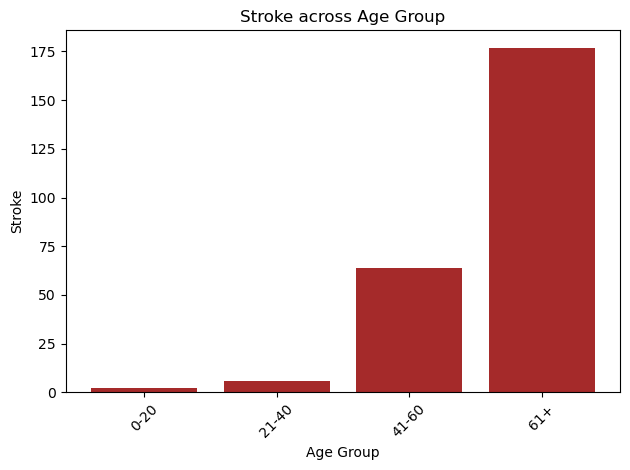

In [42]:
Stroke_by_Age_Group = df.groupby('Age Group')['Stroke'].sum().reset_index()
plt.bar(Stroke_by_Age_Group['Age Group'],Stroke_by_Age_Group ['Stroke'],color = 'brown')
plt.title('Stroke across Age Group')
plt.ylabel('Stroke')
plt.xlabel('Age Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.3 Hypertension

In [43]:
Stroke_by_Hypertension = (df.groupby('Hypertension')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_Hypertension

Hypertension
Yes    13.253012
No      3.967910
Name: Stroke, dtype: float64

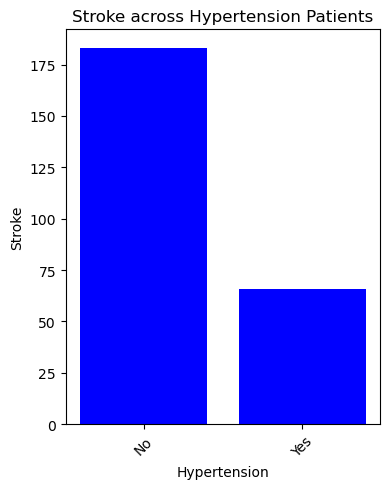

In [44]:
Hypertension = df.groupby('Hypertension')['Stroke'].sum().reset_index()
plt.figure(figsize=(4,5))
plt.bar(Hypertension['Hypertension'],Hypertension ['Stroke'],color = 'blue')
plt.title('Stroke across Hypertension Patients')
plt.ylabel('Stroke')
plt.xlabel('Hypertension')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.4 Heart disease

In [45]:
Stroke_by_Heart_Disease = (df.groupby('Heart_Disease')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_Heart_Disease

Heart_Disease
Yes    17.028986
No      4.178734
Name: Stroke, dtype: float64

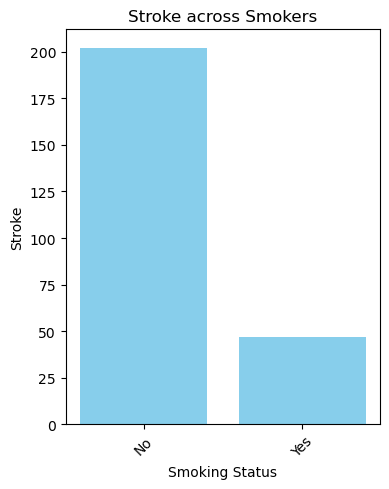

In [46]:
HDS= df.groupby('Heart_Disease')['Stroke'].sum().reset_index()
plt.figure(figsize=(4,5))
plt.bar(HDS['Heart_Disease'],HDS ['Stroke'],color = 'skyblue')
plt.title('Stroke across Smokers')
plt.ylabel('Stroke')
plt.xlabel('Smoking Status')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.5 Smoking status

In [47]:
Stroke_by_Smoking_Status = (df.groupby('Smoking_Status')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_Smoking_Status

Smoking_Status
Formerly Smoked    7.909605
Smokes             5.323194
Never Smoked       4.756871
Unknown            3.044041
Name: Stroke, dtype: float64

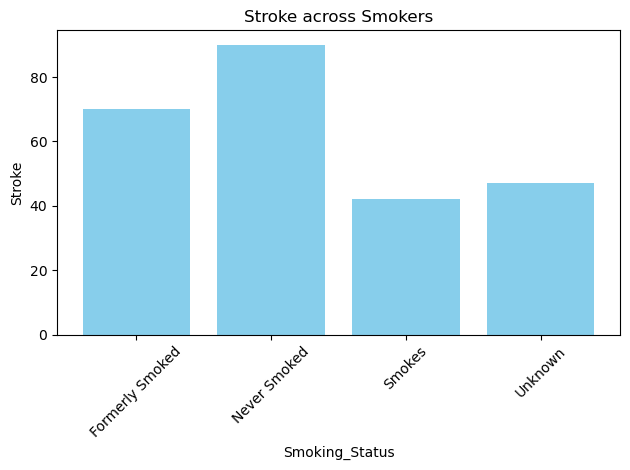

In [48]:
SS= df.groupby('Smoking_Status')['Stroke'].sum().reset_index()
plt.bar(SS['Smoking_Status'],SS ['Stroke'],color = 'skyblue')
plt.title('Stroke across Smokers')
plt.ylabel('Stroke')
plt.xlabel('Smoking_Status')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.6 Glucose level

In [49]:
Stroke_by_Glucose_Level = (df.groupby('Glucose_Level_Category')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_Glucose_Level

C:\Users\HomePC\AppData\Local\Temp\ipykernel_18404\1373791265.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Stroke_by_Glucose_Level = (df.groupby('Glucose_Level_Category')['Stroke'].mean()*100).sort_values(ascending=False)


Glucose_Level_Category
High      11.327649
Normal     3.651288
Low        3.571429
Name: Stroke, dtype: float64

### 4.7 BMI category

In [50]:
Stroke_by_BMI = (df.groupby('BMI_Category')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_BMI

C:\Users\HomePC\AppData\Local\Temp\ipykernel_18404\1766147727.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  Stroke_by_BMI = (df.groupby('BMI_Category')['Stroke'].mean()*100).sort_values(ascending=False)


BMI_Category
Overweight     7.142857
Obese          5.071315
Normal         2.941176
Underweight    0.286533
Name: Stroke, dtype: float64

### 4.8 Work type

In [51]:
Stroke_by_Work_Type = (df.groupby('Work_Type')['Stroke'].mean()*100).sort_values(ascending=False)
Stroke_by_Work_Type

Work_Type
Self Employed    7.936508
Private          5.094017
Govt Job         5.022831
Children         0.291121
Never Worked     0.000000
Name: Stroke, dtype: float64

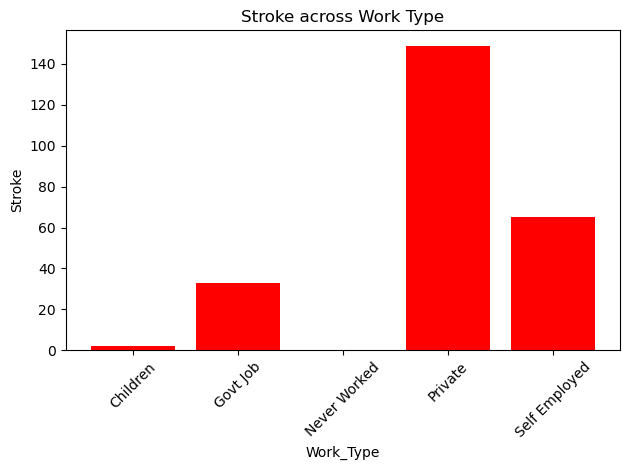

In [52]:
WBS = df.groupby('Work_Type')['Stroke'].sum().reset_index()
plt.bar(WBS['Work_Type'],WBS ['Stroke'],color = 'red')
plt.title('Stroke across Work Type')
plt.ylabel('Stroke')
plt.xlabel('Work_Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Save the cleaned dataset

In [53]:
df.to_csv('Main_Stroke_Analysis.csv',index = False)

## 6. Findings

Overall, about **4.9%** of patients in this dataset had a stroke. The groups with clearly higher rates were:

| Factor | Higher-rate group | Stroke rate | Comparison group | Stroke rate |
|---|---|---|---|---|
| Age | 61+ | 13.6% | 41-60 | 4.1% |
| Heart disease | Yes | 17.0% | No | 4.2% |
| Hypertension | Yes | 13.3% | No | 4.0% |
| Glucose level | High | 11.3% | Normal | 3.7% |

- **Age is the strongest pattern.** The rate rises sharply with age: 0.2% (0-20), 0.5% (21-40), 4.1% (41-60) and 13.6% (61+). Patients over 60 are about three times as likely to have had a stroke as those aged 41-60.
- **Heart disease** gives the highest rate of any single condition, about four times the rate of patients without it.
- **Hypertension** and **high glucose** each show a rate about three times that of the comparison group.
- **Smoking** shows a weaker pattern. Former smokers have the highest rate (7.9%), current smokers (5.3%) are only slightly above never smokers (4.8%), and the "Unknown" group is lowest (3.0%).
- **BMI** does not rise steadily. Overweight patients have the highest rate (7.1%), then Obese (5.1%) and Normal (2.9%). Underweight is almost zero (0.3%).
- **Work type:** self-employed patients have the highest rate (7.9%), with Private (5.1%) and Government jobs (5.0%) close together. Children and Never Worked are near zero.
- **Gender** shows little difference: 5.1% for males and 4.7% for females. The single patient recorded as "Other" cannot be interpreted.

**Caution:** age is likely to explain part of some of these patterns. For example, the near-zero rates for "Children" and "Unknown" smoking status probably reflect young patients, and this notebook does not separate the effect of age from the other factors.

## 7. Recommendations

- Prioritise **older patients (61+)** for stroke screening and prevention, since they show by far the highest rate.
- Within any age group, give extra attention to patients with **heart disease, hypertension or high glucose**, who show roughly three to four times the baseline rate.
- Treat the smoking, BMI and work type results as leads for further study rather than conclusions, because the patterns are weaker and may be affected by age.

## 8. Limitations

- **Observational data:** the analysis shows associations, not causes.
- **Rare outcome:** only about 4.9% of patients had a stroke, so rates for small groups are unstable. No confidence intervals or significance tests are included.
- **Age is not controlled for:** groups were not compared within the same age band, so age may explain part of the other patterns.
- **Imputed BMI:** the 201 missing values were filled with one overall median (28.1), which can blur differences between groups.
- **Simple cut-offs:** the glucose and BMI bands are basic screening ranges, not diagnoses. The BMI bands are adult cut-offs, so the Underweight group (which includes many children) should be read with care.
- **Unknown smoking status** is a large group and probably includes children.
- **Unknown source population:** the data does not say where or how patients were sampled, so results should not be generalised.

## 9. Next steps

- Logistic regression with class weighting, judged on recall, precision and ROC-AUC.
- Comparing with a tree-based model and check which features matter most.
- i will Build an interactive dashboard of these findings.

*This is an educational analysis and not medical advice.*

In [55]:
df.to_csv("Stroke_main_analysis_SFRA", index=False)